In [35]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [54]:
from pydantic import BaseModel,Field

class graphSchema(BaseModel):
    topic:str= Field(description="the topic of the post")
    post:str=Field(description="The linkedIn post content")
    curated_post:str=Field(descripition="The curated LinkedIn post content")

/var/folders/z5/w1qdwj6j7d354_1rdbffm3d80000gn/T/ipykernel_41441/4119322062.py:6: PydanticDeprecatedSince20: Using extra keyword arguments on `Field` is deprecated and will be removed. Use `json_schema_extra` instead. (Extra keys: 'descripition'). Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  curated_post:str=Field(descripition="The curated LinkedIn post content")


In [56]:
demo_obj=graphSchema(
    topic="The importance of data privacy in digtal world",
    post="Data privacy is important in digital worl wit the invcreasig amount of personal information",
    curated_post="In teh digital age data privacy is more important than ever"
)

print(demo_obj)

topic='The importance of data privacy in digtal world' post='Data privacy is important in digital worl wit the invcreasig amount of personal information' curated_post='In teh digital age data privacy is more important than ever'


In [71]:
def create_post(state:graphSchema) -> graphSchema:
    
    topic=state.topic
    post=llm.invoke(f"create a linkedIn post about {topic}").content
    state.post=post

    return state


In [72]:
def curated_post(state:graphSchema) -> graphSchema:
    post=state.post

    state.curated_post=llm.invoke(f"hey curate the attched post with genz tone {post}").content

    return state

In [73]:
from langgraph.graph import StateGraph, START, END

graph=StateGraph(graphSchema)

graph.add_node('create_post',create_post)
graph.add_node('curated_post', curated_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post","curated_post")
graph.add_edge("curated_post",END)


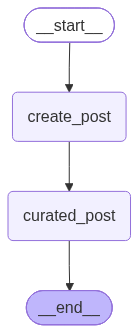

In [74]:
## compile the graph 

from IPython.display import Image, display

pydantic_graph=graph.compile()


Image(pydantic_graph.get_graph().draw_mermaid_png())

In [75]:
pydantic_graph.invoke({
    "topic":"talk about fifa world cup final 2026 and why did argentina lose the match",
     "post":"", 
     "curated_post":""})

{'topic': 'talk about fifa world cup final 2026 and why did argentina lose the match',
 'post': 'Here’s a LinkedIn-style post you can use:\n\n---\n\nThe FIFA World Cup Final 2026 was a reminder that football is as much about preparation, pressure, and precision as it is about passion.\n\nArgentina’s loss in the final was disappointing for fans, but it also highlighted how small margins decide the biggest games. At this level, one tactical adjustment, one missed chance, or one moment of defensive hesitation can change everything.\n\nWhat stood out most was how the match reflected the realities of elite performance:\n- Composure under pressure matters\n- Tactical discipline is non-negotiable\n- Execution in key moments defines outcomes\n- Even the strongest teams can be undone by details\n\nArgentina came into the final with huge expectations, but the pressure of the occasion, the opponent’s game plan, and the inability to fully capitalize on key opportunities all contributed to the resu